#LLM - Klasyczne metody klasyfikacji tekstu - LAB

#Zadanie

Zaadaptuj kod z notatnika *LLM - Klasyczne metody klasyfikacji tekstu - Omówienie* do problemu klasyfikacji liczby gwiazdek dla opinii z serwisu Yelp.
Możesz przygotować pętlę treningową albo w czystym PyTorchu, albo z wykorzystaniem biblioteki PyTorch Lightning.

* Wykorzystaj zbiór `Yelp/yelp_review_full` ([link](https://huggingface.co/datasets/Yelp/yelp_review_full)) zawierający opinie z serwisu Yelp (kolumna: `text`) i etykietę (kolumna: `label`) o wartościach $0,1,2,3,4$ określającą liczbę gwiazdek przyznaną przez użytkownika (a ściślej, liczbę gwiazdek minus jeden). Ponieważ mamy pięć klas, ostatnia warstwa liniowa w sieci neuronowej musi zwracać pięć wartości.
    * Zgodnie z dobrą praktyką z części treningowej wydziel dodatkową część walidacyjną i testową.
    * Ogranicz rozmiar każdej części zbioru danych (treningowej, walidacyjnej i testowej). Część treningowa nie powinna zawierać więcej niż 100k elementów.
* Do ekstrakcji cech z tekstu wykorzystaj **metodę TF-IDF** (*term frequency-inverse document frequency*) opartą o podejście typu worek słów (*bag-of-words*). Zastosuj funkcję `TfidfVectorizer` z biblioteki `scikit-learn`.
* Wykorzystaj podobną architekturę sieci (perceptron wielowarstwowy z warstwą Dropout) jak w notatniku wykładowym.



## Punkty do wykonania

1.   Napisz funkcję znajdującą i wyświetlającą $k$ elementów zbioru testowego dla których model najbardziej się myli, czyli estymuje najmniejsze prawdopodobieństwa prawdziwej klasy. Softmax jest funkcją ściśle rosnącą, więc wystarczy znaleźć elementy z najmniejszą wartością nieznormalizowanego wyjścia z sieci (logita) dla prawdziwej klasy.
2.   Zbadaj wpływ wybranych parametrów funkcji ekstrakcji cech z tekstu `TfidfVectorizer` na skuteczność wytrenowanego modelu. Uruchom kilka eksperymentów z różnymi wartościami parametrów i porównaj dokładność wytrenowanego modelu na zbiorze walidacyjnym.
3.   Zbadaj wpływ wybranych hiperparametrów modelu (np. liczba warstw liniowych modelu, rozmiary warstw) i procesu uczenia (np. początkowa wartość stopy uczenia, liczba epok, typ i parametry planisty stopy uczenia, typ i parametry optymalizatora) na skuteczność wytrenowanego modelu. Uruchom kilka eksperymentów z różnymi wartościami hiperparametrów i porównaj dokładność wytrenowanego modelu na zbiorze walidacyjnym. Następnie wykonaj finalną ewaluację najlepszego modelu na zbiorze testowym.


##Przygotowanie środowiska
Upewnij się, że notatnik jest uruchomiony na maszynie z GPU. Jesli GPU nie jest dostępne zmień typ maszyny (Runtime | Change runtime type) i wybierz T4 GPU.

In [ ]:
# !nvidia-smi

Instalacja dodatkowych bibliotek: datasets (z biblioteki HuggingFace), TorchMetrics i W&B (Weights and Biases) Models.

In [51]:
!pip install -q datasets
!pip install -q torchmetrics
!pip install -q wandb

Import bibliotek.

In [52]:
import torch
import numpy as np
import matplotlib.pyplot as plt

print(f"Wersja biblioteki PyTorch: {torch.__version__}")

Wersja biblioteki PyTorch: 2.10.0


Sprawdzenie dostępności GPU.

In [53]:
print(f"Dostępność GPU CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Typ GPU: {torch.cuda.get_device_name(0)}")

print(f"Dostępność GPU MPS: {torch.mps.is_available()}")

Dostępność GPU CUDA: False
Dostępność GPU MPS: True


In [ ]:
# import wandb

# # Logowanie do serwisu Weights&Biases monitorującego przebieg eksperymentów
# wandb.login()

# Solution

## Data processing and analyzation

In [54]:
from datasets import load_dataset


dataset = load_dataset("Yelp/yelp_review_full")

test_dataset = dataset["test"]
train_val_dataset = dataset["train"].train_test_split(test_size=0.2)
train_dataset = train_val_dataset["train"]
val_dataset = train_val_dataset["test"]

print(train_dataset.shape)
print(val_dataset.shape)
print(test_dataset.shape)

train_dataset = train_dataset.shuffle(seed=42).select(range(int(len(train_dataset)*0.15)))
val_dataset = val_dataset.shuffle(seed=42).select(range(int(len(val_dataset)*0.15)))
test_dataset = test_dataset.shuffle(seed=42).select(range(int(len(test_dataset)*0.15)))

print(f"Liczba próbek w zbiorze treningowym: {len(train_dataset)}")
print(f"Liczba próbek w zbiorze walidacyjnym: {len(val_dataset)}")
print(f"Liczba próbek w zbiorze testowym: {len(test_dataset)}")

(520000, 2)
(130000, 2)
(50000, 2)
Liczba próbek w zbiorze treningowym: 78000
Liczba próbek w zbiorze walidacyjnym: 19500
Liczba próbek w zbiorze testowym: 7500


In [55]:
id = int(np.random.choice(range(len(train_dataset))))
print(f"Row={id}")
sample = train_dataset[id]
print(f"{sample['text']=}")
print(f"{sample['label']=}")

Row=50120
sample['text']="Time to update my review.  All of my previous comments still apply....WiFi sucks, Car Rental building is far from the airport and takes a very long time to get to.  However, it's improved in 1 important area and gets bumped up 1 Star for it....the food has improved in the gate areas.\\n\\nSince my last review, they've added local Arizona restaurants like La Grande Orange and Sir Veza's Taco Garage.  Awesome move by the airport.  At least we're doing something right here.\\n\\nAlso, they've added an art display in the gate area before security.  Over the Summer they had bolo ties on display from all over the State.  Very cool.\\n\\nLet's keep improving this airport.  Now if they can just move car rental on-site...\\n\\nReturn Factor - 100%"
sample['label']=2


Unique labels: [0 1 2 3 4], Number of unique labels: 5



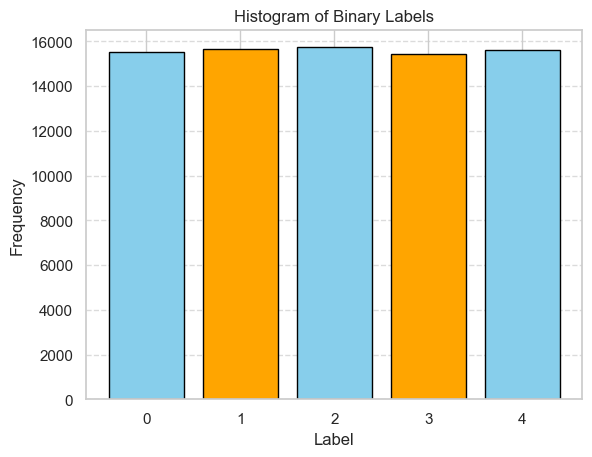

In [56]:
# Count occurrences of each label
unique_labels, counts = np.unique(train_dataset['label'], return_counts=True)
labels_num = len(unique_labels)
print(f"Unique labels: {unique_labels}, Number of unique labels: {labels_num}\n")

# Plot histogram
plt.bar(unique_labels, counts, color=['skyblue', 'orange'], edgecolor='black')
plt.title('Histogram of Binary Labels')
plt.xlabel('Label')
plt.ylabel('Frequency')
plt.xticks(unique_labels)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [58]:
vocab_size = 1000

vectorizer = TfidfVectorizer(
    max_features=vocab_size,
    lowercase=True,
    analyzer="word",
    ngram_range=(1, 1),
    stop_words="english"
)

train_features = vectorizer.fit_transform(train_dataset["text"])

val_features = vectorizer.transform(val_dataset["text"])
test_features = vectorizer.transform(test_dataset["text"])

In [59]:
print(f"TF-IDF Matric size for train dataset: {train_features.shape}")   # 78 000 rows - number of documents in (language) corpus, 1 000 columns - number of word features with weights
print(f"{train_features.dtype=}\n")

feature_names = vectorizer.get_feature_names_out()
print(f"Extracted features number: {len(feature_names)}")
print(f"Sample features: {np.random.choice(feature_names, 30)}\n")

TF-IDF Matric size for train dataset: (78000, 1000)
train_features.dtype=dtype('float64')

Extracted features number: 1000
Sample features: ['prime' 'drive' 'sat' 'better' 'stuff' 'chain' 'nbut' 'seasoned' 'eye'
 'loved' 'ask' 'chose' 'past' 'expecting' 'simply' 'liked' 'forget'
 'minutes' 'taco' 'hear' 'fact' '24' 'la' 'sure' 'near' 'window' 'ready'
 'management' 'pancakes' 'simple']



In [60]:
ndx = int(np.random.choice(range(len(train_dataset))))
print(f"Train dataset element with index={ndx}")
print(f"{train_dataset['text'][ndx]=}\n")

features = train_features[ndx]  # features extracted from document of `ndx` index out of 78 000 documents in language corpus
print(f"No-filtered features: {features}\n")  # Compressed Sparse Row sparse matrix ... shape (1, 1000) -> each feature is addressed like (0, 356)

print(f"Features of element with index={ndx}:")
non_zero_cols = features.nonzero()[1]

non_zero_cols = sorted(non_zero_cols)
for i in non_zero_cols:
    print(f"Column: {i} ({feature_names[i]})   Weight: {features[0, i]:.5f}") # coords od each feature in row/document is (0, <column_numb>)

Train dataset element with index=20657
train_dataset['text'][ndx]="This BWW always manages to screw up the order if you call it in to pick it up. Why Bdubs doesn't let you order online like their competition, I'll never know but it gets really old having to wait everytime you go in for them to fix the mistake and deal with poor customer service."

No-filtered features: <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 19 stored elements and shape (1, 1000)>
  Coords	Values
  (0, 234)	0.2288822572455393
  (0, 464)	0.1172311257143936
  (0, 772)	0.12435099449988347
  (0, 442)	0.1682307815657987
  (0, 695)	0.13634996386410128
  (0, 944)	0.18363389708093572
  (0, 595)	0.21057709344110867
  (0, 474)	0.18694860001988126
  (0, 459)	0.21140357650086272
  (0, 206)	0.23420378886932616
  (0, 382)	0.22003348394306005
  (0, 606)	0.3330511378614214
  (0, 195)	0.21096447411817337
  (0, 342)	0.25993668964546657
  (0, 310)	0.2846585141853152
  (0, 642)	0.25389737658844924
  (0, 663)	0.260204

Mean of non-zero features in samples: 32.40


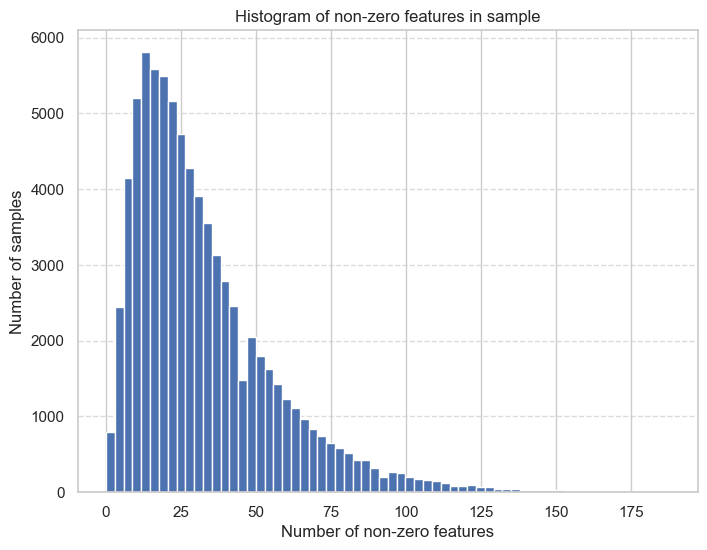

In [61]:
non_zero_counts = np.diff(train_features.indptr)
print(f"Mean of non-zero features in samples: {non_zero_counts.mean():.2f}")  # średnia liczba cech wyodrębnionych per dokument z korpusu językowego (średnia wartość dla 1 z 67 200)

# Plot histogram
plt.figure(figsize=(8, 6))
plt.hist(non_zero_counts, bins=64)
plt.title('Histogram of non-zero features in sample')
plt.xlabel('Number of non-zero features')
plt.ylabel('Number of samples')
plt.grid(axis='y', linestyle='--', alpha=0.7)

In [62]:
import torch

from torch.utils.data import TensorDataset, DataLoader

In [63]:
def make_dataset(sparse_features, labels):
    dense_features = sparse_features.astype(np.float32).todense()     # scipy.sparse.spmatrix.todense() --> numpy.matrix
    dataset = TensorDataset(
        torch.from_numpy(dense_features),
        torch.tensor(labels, dtype=torch.int64)
    )
    return dataset


# print(type(train_features))           # type: scipy.sparse._csr.csr_matrix
# print(type(train_dataset['label']))   # type: datasets.arrow_dataset.Column

datasets = {
    'train': make_dataset(train_features, train_dataset['label']),
    'val': make_dataset(val_features, val_dataset['label']),
    'test': make_dataset(test_features, test_dataset['label'])
}

print(datasets['train'][0])

(tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.2115, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.3819, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.2256, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000,

In [64]:
batch_size = 128

data_loaders = {stage: DataLoader(datasets[stage], shuffle=stage=="train", num_workers=0, batch_size=batch_size) for stage in datasets}

In [65]:
for X_batch, y_batch in data_loaders['train']:
    print(f"{X_batch.shape=}")
    print(f"{y_batch.shape=}")
    break

X_batch.shape=torch.Size([128, 1000])
y_batch.shape=torch.Size([128])


## Stage 0 - basic model + train loop + helper functions definion

In [66]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.mps.is_available() else "cpu")
print(f"Device: {device}")

Device: mps


In [72]:
import torch.nn as nn


class RatingClassifier(nn.Module):
    def __init__(self, vocab_size: int, n_classes: int):
        super().__init__()
        self.vocab_size = vocab_size
        self.n_classes = n_classes

        self.feature_extractor = nn.Sequential(
            nn.Linear(self.vocab_size, 64),
            nn.LeakyReLU(),
            nn.Linear(64, 128),
            nn.LeakyReLU(),
            nn.Linear(128, 32),
            nn.LeakyReLU(),
        )
        self.dropout = nn.Dropout(0.1)
        self.linear = nn.Linear(32, n_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        features = self.feature_extractor(x)
        features = self.dropout(features)
        logits = self.linear(features)
        return logits

#### Model Training loop

In [ ]:
import torch.nn as nn
import torchmetrics
from tqdm import tqdm


def train(model: nn.Module, loaders: dict[DataLoader], criterion: nn.Module,
          optimizer: torch.optim.Optimizer, lr_scheduler, num_epochs: int):

    accumulated_loss = []
    accumulated_acc = []

    metric_loss = torchmetrics.aggregation.MeanMetric().to(device)
    metric_acc = torchmetrics.classification.Accuracy(task="multiclass", num_classes=labels_num).to(device)

    # val_loss = np.array(np.inf)
    # overfitting_counter = 0

    for epoch in range(1, num_epochs+1):

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            for X_batch, target in tqdm(loaders[phase]):

                X_batch, target = X_batch.to(device), target.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    logits = model(X_batch)
                    # dim=1, as columns (dim=1) are 'squeezed' to one max value
                    _, preds = torch.max(logits, dim=1)   # torch.max() --> [values, indices] - pred is index of max value as in softmax highest value will have highest prob as well
                    loss = criterion(logits, target)

                    metric_loss(loss)
                    metric_acc(preds, target)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

            acc = metric_acc.compute()
            mean_loss = metric_loss.compute()
            current_lr = lr_scheduler.get_last_lr()[0]

            # if phase == "val":
            #     if mean_loss.to_numpy() > val_loss:
            #         overfitting_counter += 1
            #     else:
            #         val_loss = mean_loss.to_numpy()

            print(f"(Epoch {epoch}/[{phase}]) Loss:\t{mean_loss:.3f}   Accuracy: {acc:.3f}   lr: {current_lr}")
            metrics = {
                f"{phase}/loss": mean_loss,
                f"{phase}/accuracy": acc,
                f"{phase}/lr": current_lr,
            }
            # wandb.log(metrics, step=epoch)

            if phase == "val":
                accumulated_loss.append(float(mean_loss.cpu()))
                accumulated_acc.append(float(acc.cpu()))

            metric_loss.reset()
            metric_acc.reset()

            # if overfitting_counter > 5:
            #     break

        lr_scheduler.step()

    return accumulated_loss, accumulated_acc


In [ ]:
def find_worst_predictions(logits: torch.Tensor, targets: torch.Tensor, k=5):
    logit_per_true_class = logits.gather(dim=1, index=targets.view(-1, 1)).squeeze(1)
    values, indices = torch.topk(logit_per_true_class, k=k, largest=False)
    return values, indices

In [69]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


def plot_confusion_matrix(targets, preds):
    cm = confusion_matrix(targets, preds, normalize="true")
    plt.figure(figsize=(10, 8))
    classes = list(range(labels_num))
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', 
                xticklabels=classes, yticklabels=classes)
    plt.xlabel("Prediction")
    plt.ylabel("True class")
    plt.title("Confussion matrix")
    plt.show()



In [70]:
def plot_comparison(metric_dict, title, ylabel):
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(10, 6))

    for model_name, metrics_val in metric_dict.items():
        epochs = range(1, len(metrics_val) + 1)
        plt.plot(epochs, metrics_val, label=model_name, linewidth=2, marker='o', markersize=4)

    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel("Epoch", fontsize=12)
    plt.ylabel(ylabel, fontsize=12)

    plt.grid(True, linestyle='--', alpha=0.7)

    plt.legend(loc='upper right', frameon=True)

    # plt.yscale('log')

    plt.tight_layout()
    plt.show()

## Stage 1 - simple test model training + finding `k` worst preds for true class

In [73]:
classifier = RatingClassifier(vocab_size, n_classes=labels_num)
classifier.to(device)

print(classifier)

RatingClassifier(
  (feature_extractor): Sequential(
    (0): Linear(in_features=1000, out_features=64, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=64, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=32, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=32, out_features=5, bias=True)
)


In [74]:
num_epochs = 30

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(classifier.parameters(), lr=1e-4, weight_decay=1e-5)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-5)

In [75]:
# run = wandb.init(project="MyExperiments")

_, _ = train(classifier, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)

# run.finish()

100%|██████████| 610/610 [00:04<00:00, 141.08it/s]


(Epoch 1/[train]) Loss:	1.462   Accuracy: 0.321   lr: 0.0001


100%|██████████| 153/153 [00:00<00:00, 211.14it/s]


(Epoch 1/[val]) Loss:	1.206   Accuracy: 0.456   lr: 0.0001


100%|██████████| 610/610 [00:03<00:00, 160.83it/s]


...

(Epoch 29/[val]) Loss:	1.057   Accuracy: 0.538   lr: 1.0983357966978745e-05


100%|██████████| 610/610 [00:03<00:00, 154.76it/s]


(Epoch 30/[train]) Loss:	1.027   Accuracy: 0.554   lr: 1.0246514708427697e-05


100%|██████████| 153/153 [00:00<00:00, 193.14it/s]

(Epoch 30/[val]) Loss:	1.057   Accuracy: 0.540   lr: 1.0246514708427697e-05


In [77]:
logits_l = []
preds_l = []
targets_l = []
input_l = []

classifier.eval()
with torch.inference_mode():
    for X_batch, target in tqdm(data_loaders['test']):
        X_batch, target = X_batch.to(device), target.to(device)
        logits = classifier(X_batch)
        _, preds = torch.max(logits, dim=-1)
        preds_l.append(preds.cpu())
        logits_l.append(logits.cpu())
        targets_l.append(target.cpu())
        input_l.append(X_batch.cpu())

all_logits = torch.cat(logits_l, dim=0)
all_preds = torch.cat(preds_l, dim=0)
all_targets = torch.cat(targets_l, dim=0)
all_input = torch.cat(input_l, dim=0)

find_worst_predictions(all_logits, all_targets)

100%|██████████| 59/59 [00:00<00:00, 359.15it/s]


(tensor([-4.3063, -4.2281, -3.5333, -3.2004, -3.1568]),
 tensor([1710, 5240, 6155, 3125, 5760]))

## Stage 2 - finding best Vectorizer params

In [79]:
from dataclasses import dataclass, asdict


@dataclass
class VectorizerParams:
      max_features: int
      lowercase: bool
      analyzer: str
      ngram_range: tuple[int, int]
      stop_words: str = "english"



def prep_dataloaders(params: VectorizerParams, datasets: list, batch_size: int = 128):

    vectorizer = TfidfVectorizer(**asdict(params))

    train_dataset, val_dataset, test_dataset = datasets

    train_features = vectorizer.fit_transform(train_dataset["text"])

    val_features = vectorizer.transform(val_dataset["text"])
    test_features = vectorizer.transform(test_dataset["text"])


    datasets = {
        'train': make_dataset(train_features, train_dataset['label']),
        'val': make_dataset(val_features, val_dataset['label']),
        'test': make_dataset(test_features, test_dataset['label'])
    }

    batch_size = 128

    return {stage: DataLoader(datasets[stage], shuffle=stage=="train", num_workers=0, batch_size=batch_size) for stage in datasets}


In [80]:
vectorizers = [
    VectorizerParams(max_features=100, lowercase=True, analyzer="word", ngram_range=(1, 1)),
    VectorizerParams(max_features=1000, lowercase=False, analyzer="word", ngram_range=(1, 2)),
    VectorizerParams(max_features=1000, lowercase=True, analyzer="word", ngram_range=(2, 2)),
    VectorizerParams(max_features=10000, lowercase=True, analyzer="word", ngram_range=(1, 1)),
    VectorizerParams(max_features=10000, lowercase=True, analyzer="word", ngram_range=(1, 3))
]

RatingClassifier(
  (feature_extractor): Sequential(
    (0): Linear(in_features=100, out_features=64, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=64, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=32, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=32, out_features=5, bias=True)
)


100%|██████████| 610/610 [00:03<00:00, 153.71it/s]


(Epoch 1/[train]) Loss:	1.562   Accuracy: 0.264   lr: 0.0001


100%|██████████| 153/153 [00:00<00:00, 207.96it/s]


(Epoch 1/[val]) Loss:	1.416   Accuracy: 0.361   lr: 0.0001


...

(Epoch 9/[val]) Loss:	1.009   Accuracy: 0.563   lr: 1.8594235253127375e-05


100%|██████████| 610/610 [00:06<00:00, 95.07it/s] 


(Epoch 10/[train]) Loss:	0.895   Accuracy: 0.611   lr: 1.2202456766718093e-05


100%|██████████| 153/153 [00:01<00:00, 104.40it/s]


(Epoch 10/[val]) Loss:	1.007   Accuracy: 0.565   lr: 1.2202456766718093e-05


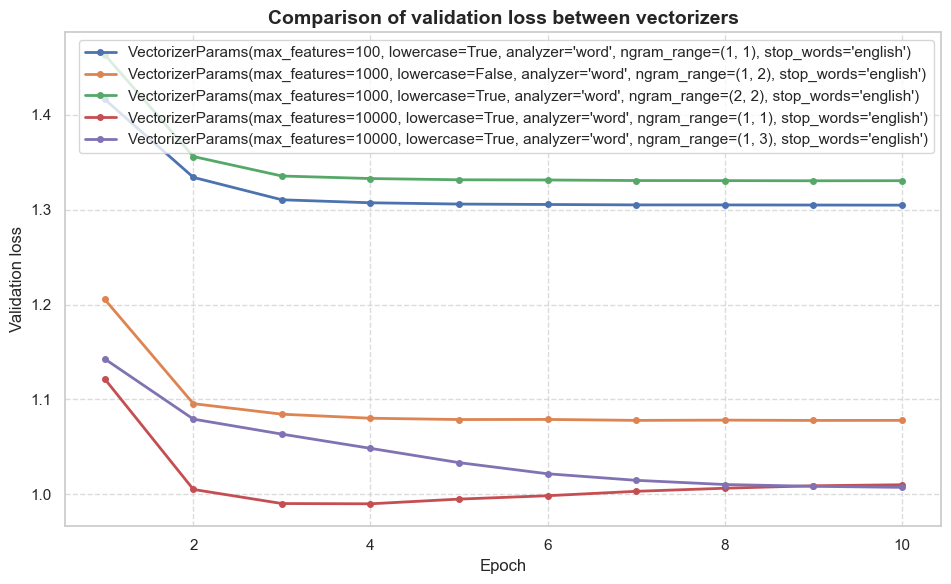

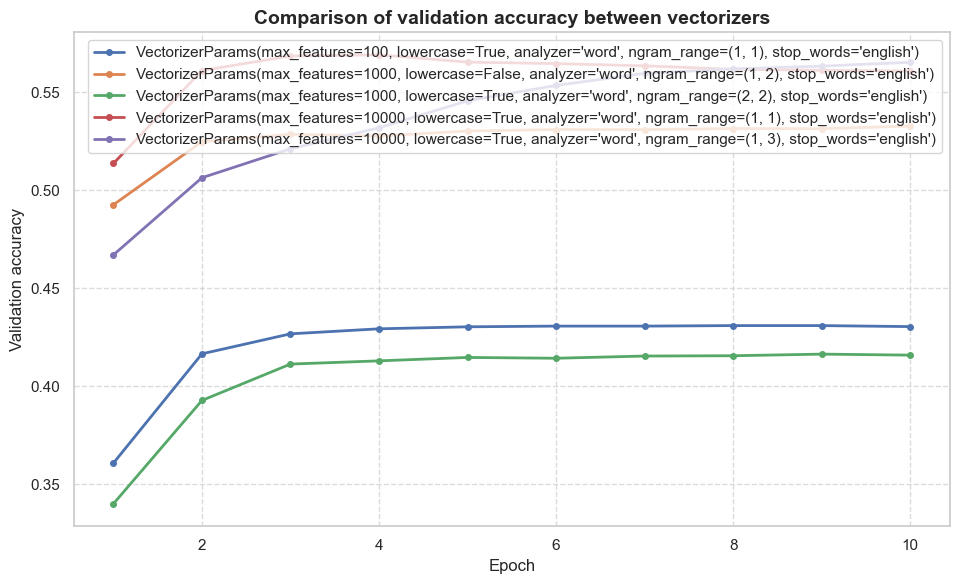

In [82]:
all_tested_losses = {}
all_tested_acc = {}

datasets = (train_dataset, val_dataset, test_dataset)
num_epochs = 10

for vectorizer in vectorizers:
    classifier = RatingClassifier(vectorizer.max_features, n_classes=labels_num)
    classifier.to(device)

    print(classifier)

    data_loaders = prep_dataloaders(vectorizer, datasets)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(classifier.parameters(), lr=1e-4, weight_decay=1e-5)
    lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-5)


    accumulated_loss, accumulated_acc = train(classifier, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)
    all_tested_losses[str(vectorizer)] = accumulated_loss
    all_tested_acc[str(vectorizer)] = accumulated_acc


plot_comparison(all_tested_losses, title="Comparison of validation loss between vectorizers", ylabel="Validation loss")
plot_comparison(all_tested_acc, title="Comparison of validation accuracy between vectorizers", ylabel="Validation accuracy")


#### Training + Evaluation on test dataset for data transformed by best found vectorizer 

In [83]:
vectorizer = VectorizerParams(max_features=10000, lowercase=True, analyzer="word", ngram_range=(1, 3))

classifier = RatingClassifier(vectorizer.max_features, n_classes=labels_num)
classifier.to(device)

print(classifier)

data_loaders = prep_dataloaders(vectorizer, datasets)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(classifier.parameters(), lr=1e-4, weight_decay=1e-5)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-5)


_, _ = train(classifier, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)

RatingClassifier(
  (feature_extractor): Sequential(
    (0): Linear(in_features=10000, out_features=64, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=64, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=32, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=32, out_features=5, bias=True)
)


100%|██████████| 610/610 [00:07<00:00, 82.88it/s]


(Epoch 1/[train]) Loss:	1.433   Accuracy: 0.357   lr: 0.0001


100%|██████████| 153/153 [00:01<00:00, 101.95it/s]


(Epoch 1/[val]) Loss:	1.134   Accuracy: 0.487   lr: 0.0001


...

(Epoch 9/[val]) Loss:	0.985   Accuracy: 0.575   lr: 1.8594235253127375e-05


100%|██████████| 610/610 [00:06<00:00, 88.01it/s]


(Epoch 10/[train]) Loss:	0.848   Accuracy: 0.634   lr: 1.2202456766718093e-05


100%|██████████| 153/153 [00:01<00:00, 113.05it/s]


(Epoch 10/[val]) Loss:	0.986   Accuracy: 0.576   lr: 1.2202456766718093e-05


100%|██████████| 59/59 [00:00<00:00, 72.45it/s] 


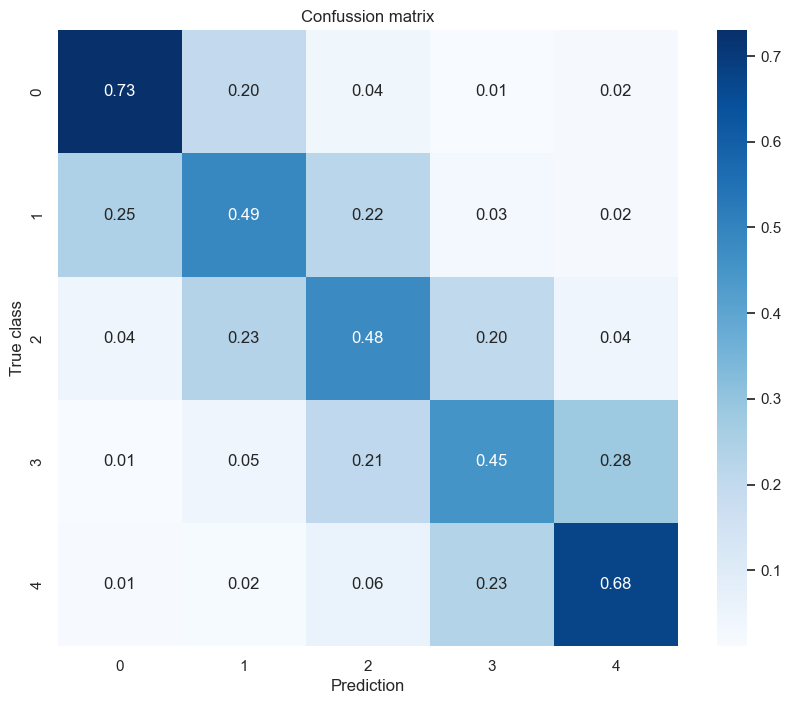

In [84]:
logits_l = []
preds_l = []
targets_l = []
input_l = []

classifier.eval()
with torch.inference_mode():
    for X_batch, target in tqdm(data_loaders['test']):
        X_batch, target = X_batch.to(device), target.to(device)
        logits = classifier(X_batch)
        _, preds = torch.max(logits, dim=-1)
        preds_l.append(preds.cpu())
        logits_l.append(logits.cpu())
        targets_l.append(target.cpu())
        input_l.append(X_batch.cpu())

all_logits = torch.cat(logits_l, dim=0)
all_preds = torch.cat(preds_l, dim=0)
all_targets = torch.cat(targets_l, dim=0)
all_input = torch.cat(input_l, dim=0)

plot_confusion_matrix(all_targets.numpy(), all_preds.numpy())

## Stage 3 - finding best model hiperparams and training stage params

#### New test models with different varianions of neurons number (hidden layers size) and hidden layers number

In [90]:
import torch.nn as nn


class RatingClassifierExtendedV1(nn.Module):
    def __init__(self, vocab_size: int, n_classes: int):
        super().__init__()
        self.vocab_size = vocab_size
        self.n_classes = n_classes

        self.feature_extractor = nn.Sequential(
            nn.Linear(self.vocab_size, 32),
            nn.LeakyReLU(),
        )
        self.dropout = nn.Dropout(0.1)
        self.linear = nn.Linear(32, n_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        features = self.feature_extractor(x)
        features = self.dropout(features)
        logits = self.linear(features)
        return logits
    

class RatingClassifierExtendedV2(nn.Module):
    def __init__(self, vocab_size: int, n_classes: int):
        super().__init__()
        self.vocab_size = vocab_size
        self.n_classes = n_classes

        self.feature_extractor = nn.Sequential(
            nn.Linear(self.vocab_size, 256),
            nn.LeakyReLU(),
            nn.Linear(256, 128),
            nn.LeakyReLU(),
            nn.Linear(128, 64),
            nn.LeakyReLU(),
            nn.Linear(64, 32),
            nn.LeakyReLU(),
            nn.Linear(32, 16),
            nn.LeakyReLU(),
        )
        self.dropout = nn.Dropout(0.1)
        self.linear = nn.Linear(16, n_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        features = self.feature_extractor(x)
        features = self.dropout(features)
        logits = self.linear(features)
        return logits


In [91]:
vocab_size = 10000

vectorizer = TfidfVectorizer(
    max_features=vocab_size,
    lowercase=True,
    analyzer="word",
    ngram_range=(1, 3),
    stop_words="english"
)

train_features = vectorizer.fit_transform(train_dataset["text"])

val_features = vectorizer.transform(val_dataset["text"])
test_features = vectorizer.transform(test_dataset["text"])


datasets = {
    'train': make_dataset(train_features, train_dataset['label']),
    'val': make_dataset(val_features, val_dataset['label']),
    'test': make_dataset(test_features, test_dataset['label'])
}

batch_size = 256

data_loaders = {stage: DataLoader(datasets[stage], shuffle=stage=="train", num_workers=0, batch_size=batch_size) for stage in datasets}

#### Find best model architecture

RatingClassifier(
  (feature_extractor): Sequential(
    (0): Linear(in_features=10000, out_features=64, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=64, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=32, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=32, out_features=5, bias=True)
)


100%|██████████| 305/305 [00:05<00:00, 56.17it/s]


(Epoch 1/[train]) Loss:	1.563   Accuracy: 0.304   lr: 0.0001


100%|██████████| 77/77 [00:01<00:00, 65.22it/s]


(Epoch 1/[val]) Loss:	1.394   Accuracy: 0.402   lr: 0.0001


...

(Epoch 9/[val]) Loss:	1.032   Accuracy: 0.554   lr: 1.8594235253127375e-05


100%|██████████| 305/305 [00:05<00:00, 55.74it/s]


(Epoch 10/[train]) Loss:	0.924   Accuracy: 0.601   lr: 1.2202456766718093e-05


100%|██████████| 77/77 [00:01<00:00, 57.04it/s]


(Epoch 10/[val]) Loss:	1.031   Accuracy: 0.554   lr: 1.2202456766718093e-05


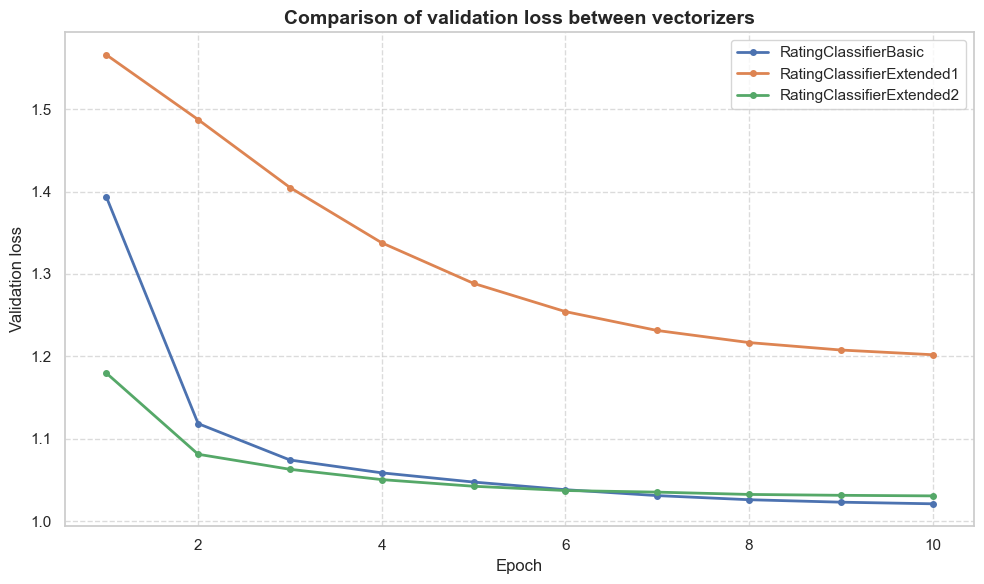

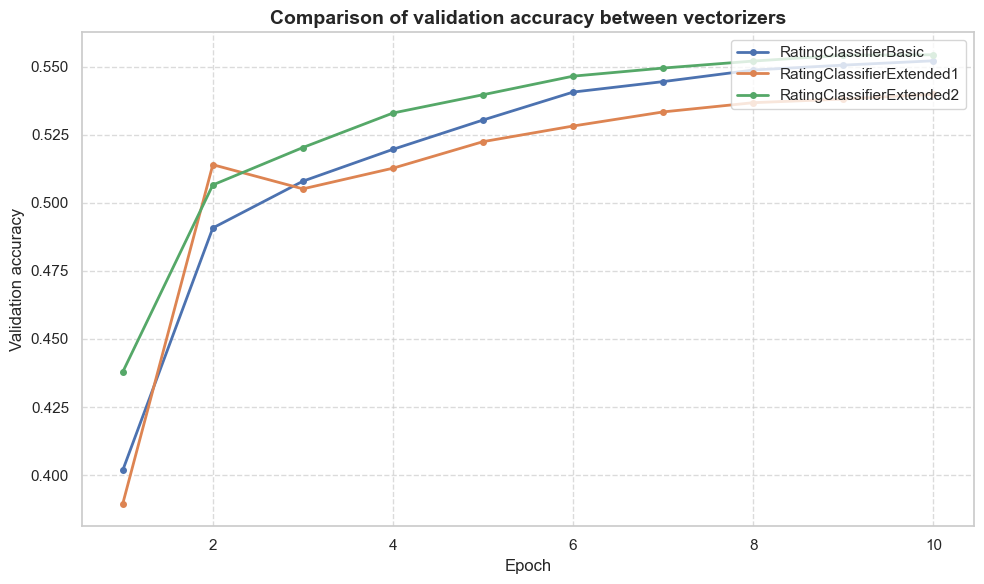

In [92]:
models = {
    "RatingClassifierBasic": RatingClassifier(vocab_size, labels_num),
    "RatingClassifierExtended1": RatingClassifierExtendedV1(vocab_size, labels_num),
    "RatingClassifierExtended2": RatingClassifierExtendedV2(vocab_size, labels_num),
}

all_tested_losses = {}
all_tested_acc = {}


num_epochs = 10

for model_alias, model in models.items():
    
    model.to(device)
    print(model)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
    lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-5)


    accumulated_loss, accumulated_acc = train(model, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)
    all_tested_losses[model_alias] = accumulated_loss
    all_tested_acc[model_alias] = accumulated_acc


plot_comparison(all_tested_losses, title="Comparison of validation loss between vectorizers", ylabel="Validation loss")
plot_comparison(all_tested_acc, title="Comparison of validation accuracy between vectorizers", ylabel="Validation accuracy")


#### Find best model hiperparams and training stage params

RatingClassifierExtendedV2(
  (feature_extractor): Sequential(
    (0): Linear(in_features=10000, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): LeakyReLU(negative_slope=0.01)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): LeakyReLU(negative_slope=0.01)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=16, out_features=5, bias=True)
)


100%|██████████| 305/305 [00:05<00:00, 51.95it/s]


(Epoch 1/[train]) Loss:	1.629   Accuracy: 0.199   lr: 1.6666666666666667e-05


100%|██████████| 77/77 [00:01<00:00, 64.25it/s]


(Epoch 1/[val]) Loss:	1.626   Accuracy: 0.201   lr: 1.6666666666666667e-05


...

(Epoch 4/[val]) Loss:	1.616   Accuracy: 0.201   lr: 0.01


100%|██████████| 305/305 [00:05<00:00, 57.03it/s]


(Epoch 5/[train]) Loss:	1.617   Accuracy: 0.199   lr: 0.01


100%|██████████| 77/77 [00:01<00:00, 61.55it/s]
/var/folders/w2/3khqjd7d1m97phfx15lm1wyr0000gn/T/ipykernel_97499/2974211122.py:7: MatplotlibDeprecationWarning: Passing label as a length 3 sequence when plotting a single dataset is deprecated in Matplotlib 3.9 and will error in 3.11.  To keep the current behavior, cast the sequence to string before passing.
  plt.plot(epochs, metrics_val, label=model_name, linewidth=2, marker='o', markersize=4)


(Epoch 5/[val]) Loss:	1.615   Accuracy: 0.201   lr: 0.01


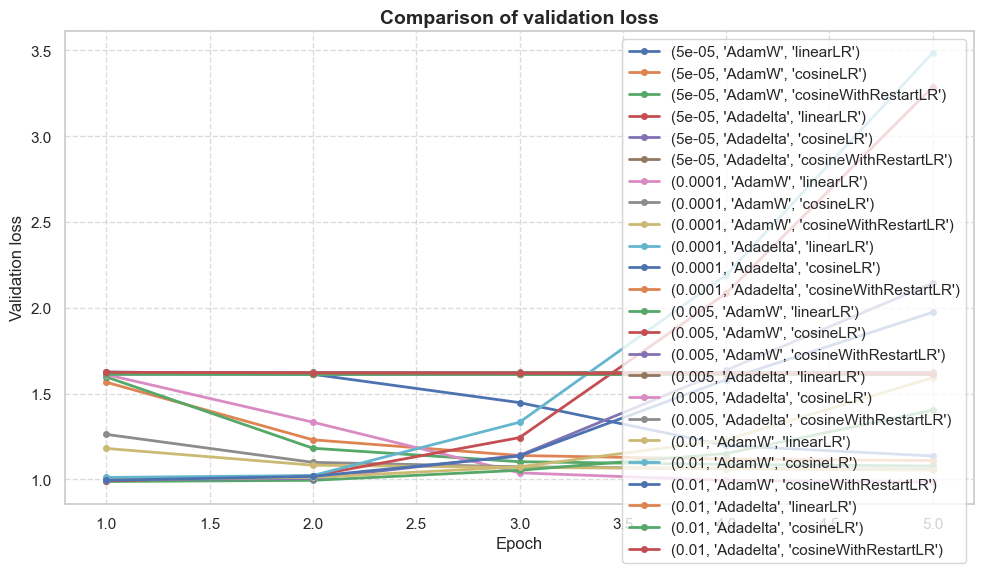

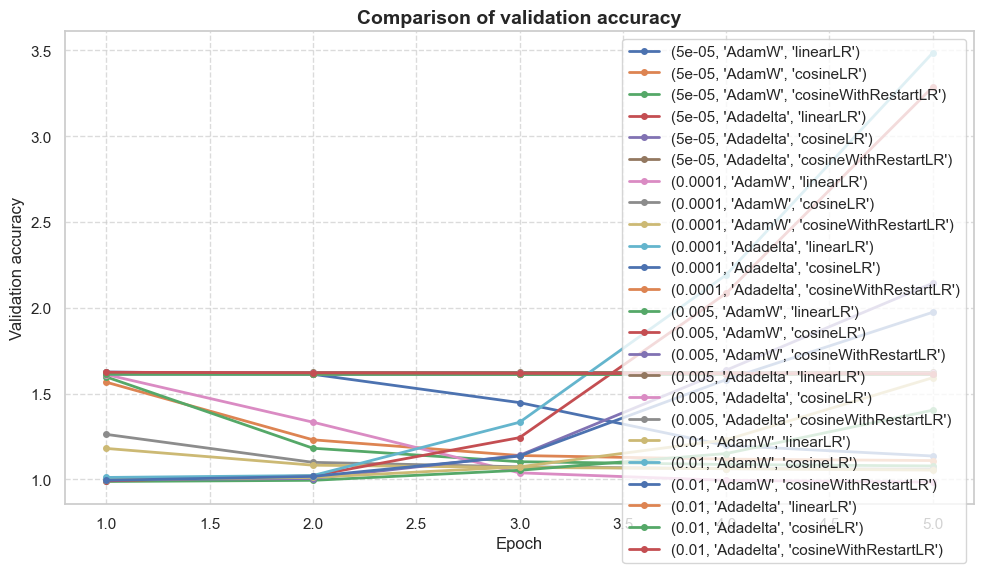

In [ ]:
from itertools import product

all_tested_losses = {}
all_tested_acc = {}

num_epochs = 5

learning_rates = [5e-5, 1e-4, 5e-3, 1e-2]
optims = [("AdamW", torch.optim.AdamW), ("Adadelta", torch.optim.Adadelta)]
schedulers = [("linearLR", torch.optim.lr_scheduler.LinearLR), ("cosineLR", torch.optim.lr_scheduler.CosineAnnealingLR), ("cosineWithRestartLR", torch.optim.lr_scheduler.CosineAnnealingWarmRestarts)]

for params in product(learning_rates, optims, schedulers):
    lr, optim, scheduler = params
    optim_alias, optimizer = optim
    scheduler_alias, lr_scheduler = scheduler

    best_model = RatingClassifierExtendedV2(vocab_size, labels_num)
    best_model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optimizer(best_model.parameters(), lr=lr, weight_decay=1e-5)
    if scheduler_alias == "linearLR":
        lr_scheduler = lr_scheduler(optimizer, total_iters=num_epochs)
    elif scheduler_alias == "cosineLR":
        lr_scheduler = lr_scheduler(optimizer, T_max=num_epochs, eta_min=1e-5)
    else:
        lr_scheduler = lr_scheduler(optimizer, T_0=1, eta_min=1e-5)

    print("Testing:\n")
    print(best_model)
    print(optimizer)
    print(f"{scheduler}\n")
        
    accumulated_loss, accumulated_acc = train(best_model, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)
    all_tested_losses[(lr, optim_alias, scheduler_alias)] = accumulated_loss
    all_tested_acc[(lr, optim_alias, scheduler_alias)] = accumulated_acc


plot_comparison(all_tested_losses, title="Comparison of validation loss", ylabel="Validation loss")
plot_comparison(all_tested_acc, title="Comparison of validation accuracy", ylabel="Validation accuracy")


In [ ]:
all_tested_losses = {}
all_tested_acc = {}

model = RatingClassifierExtendedV2(vocab_size, labels_num)
model.to(device)
print(model)
    
num_epochs = 200
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adadelta(model.parameters(), lr=5e-3, weight_decay=1e-5)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-5)
    
accumulated_loss, accumulated_acc = train(model, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)
all_tested_losses[(lr, optim_alias, scheduler_alias)] = accumulated_loss
all_tested_acc[(lr, optim_alias, scheduler_alias)] = accumulated_acc

RatingClassifierExtendedV2(
  (feature_extractor): Sequential(
    (0): Linear(in_features=10000, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): LeakyReLU(negative_slope=0.01)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): LeakyReLU(negative_slope=0.01)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=16, out_features=5, bias=True)
)
Test for epochs_num=5


100%|██████████| 305/305 [00:06<00:00, 46.88it/s]


(Epoch 1/[train]) Loss:	1.618   Accuracy: 0.200   lr: 0.005


100%|██████████| 77/77 [00:01<00:00, 67.32it/s]


(Epoch 1/[val]) Loss:	1.619   Accuracy: 0.201   lr: 0.005


...

(Epoch 299/[val]) Loss:	1.609   Accuracy: 0.201   lr: 1.054719473026048e-05


100%|██████████| 305/305 [00:04<00:00, 76.10it/s]


(Epoch 300/[train]) Loss:	1.610   Accuracy: 0.201   lr: 1.0136802433047203e-05


100%|██████████| 77/77 [00:00<00:00, 94.96it/s] 

(Epoch 300/[val]) Loss:	1.609   Accuracy: 0.201   lr: 1.0136802433047203e-05


/var/folders/w2/3khqjd7d1m97phfx15lm1wyr0000gn/T/ipykernel_97499/2974211122.py:7: MatplotlibDeprecationWarning: Passing label as a length 3 sequence when plotting a single dataset is deprecated in Matplotlib 3.9 and will error in 3.11.  To keep the current behavior, cast the sequence to string before passing.
  plt.plot(epochs, metrics_val, label=model_name, linewidth=2, marker='o', markersize=4)


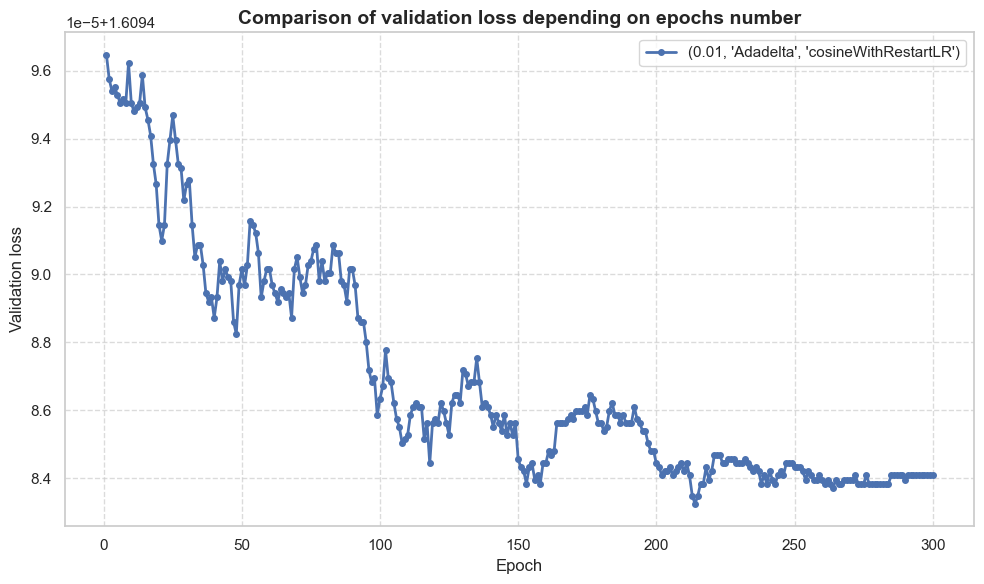

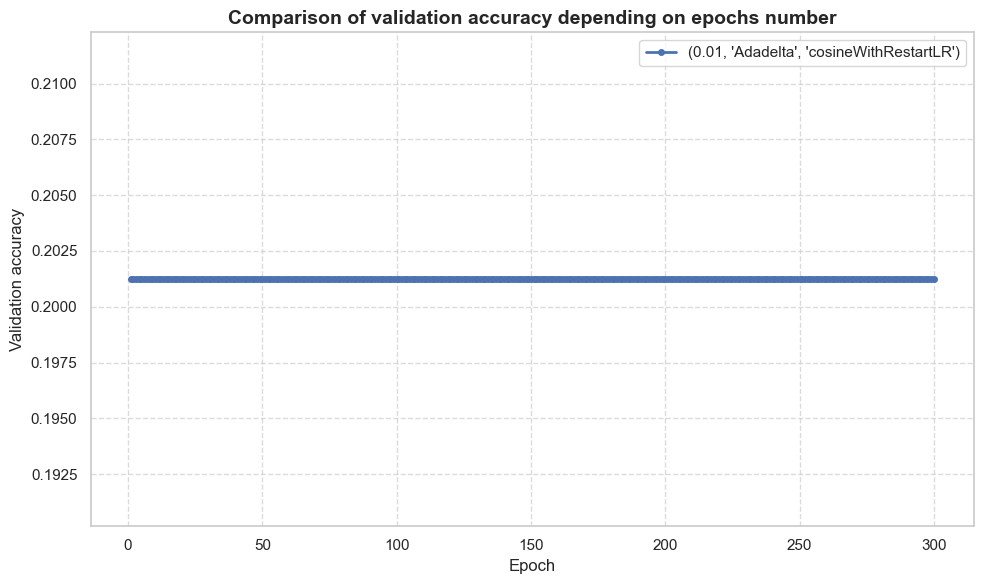

In [96]:
plot_comparison(all_tested_losses, title="Comparison of validation loss depending on epochs number", ylabel="Validation loss")
plot_comparison(all_tested_acc, title="Comparison of validation accuracy depending on epochs number", ylabel="Validation accuracy")

## Final model

### Test Model with best eval acc-loss ratio

In [ ]:
# vocab_size = 10000

# vectorizer = TfidfVectorizer(
#     max_features=vocab_size,
#     lowercase=True,
#     analyzer="word",
#     ngram_range=(1, 3),
#     stop_words="english"
# )

# train_features = vectorizer.fit_transform(train_dataset["text"])

# val_features = vectorizer.transform(val_dataset["text"])
# test_features = vectorizer.transform(test_dataset["text"])


# datasets = {
#     'train': make_dataset(train_features, train_dataset['label']),
#     'val': make_dataset(val_features, val_dataset['label']),
#     'test': make_dataset(test_features, test_dataset['label'])
# }

# batch_size = 256

# data_loaders = {stage: DataLoader(datasets[stage], shuffle=stage=="train", num_workers=0, batch_size=batch_size) for stage in datasets}

In [ ]:
model = RatingClassifierExtendedV2(vocab_size, labels_num)
model.to(device)
print(model)

num_epochs = 100
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adadelta(model.parameters(), lr=5e-3, weight_decay=1e-5)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-5)
    
accumulated_loss, accumulated_acc = train(model, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)
all_tested_losses[(lr, optim_alias, scheduler_alias)] = accumulated_loss
all_tested_acc[(lr, optim_alias, scheduler_alias)] = accumulated_acc

In [ ]:
plot_comparison(all_tested_losses, title="Comparison of validation loss", ylabel="Validation loss")
plot_comparison(all_tested_acc, title="Comparison of validation accuracy", ylabel="Validation accuracy")

In [ ]:
logits_l = []
preds_l = []
targets_l = []
input_l = []

model.eval()
with torch.inference_mode():
    for X_batch, target in tqdm(data_loaders['test']):
        X_batch, target = X_batch.to(device), target.to(device)
        logits = model(X_batch)
        _, preds = torch.max(logits, dim=-1)
        preds_l.extend(preds.cpu())
        logits_l.append(logits.cpu())
        targets_l.append(target.cpu())
        input_l.append(X_batch.cpu())

all_logits = torch.cat(logits_l, dim=0)
all_preds = torch.cat(preds_l, dim=0)
all_targets = torch.cat(targets_l, dim=0)
all_input = torch.cat(input_l, dim=0)

plot_confusion_matrix(all_targets.numpy(), all_preds.numpy())

In [ ]:
torch.save(model.state_dict(), 'my_best_model_weights.pth')